# Section 1: Imports


In [2]:
!pip -q install -U ultralytics opencv-python pyyaml matplotlib

from pathlib import Path
import cv2
import yaml
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 127.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 6.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


# Section 2: Load Dataset


In [3]:
data = check_det_dataset('african-wildlife.yaml')
root = Path(data['path'])
names = list(data['names'].values())
train_dir = root / data['train']
val_dir = root / data['val']
print(root, names)


WARNING ⚠️ Dataset 'african-wildlife.yaml' images not found, missing path '/content/datasets/african-wildlife/images/val'
Unzipping /content/datasets/african-wildlife.zip to /content/datasets/african-wildlife...: 100% ━━━━━━━━━━━━ 3018/3018 962.0files/s 3.1s
Dataset download success ✅ (4.3s), saved to /content/datasets

/content/datasets/african-wildlife ['buffalo', 'elephant', 'rhino', 'zebra']


In [4]:
def imgs(p):
    return sorted([x for x in Path(p).rglob('*') if x.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'}])
train_images, val_images = imgs(train_dir), imgs(val_dir)
print({'classes': names, 'train_images': len(train_images), 'val_images': len(val_images), 'train_path': str(train_dir), 'val_path': str(val_dir)})

{'classes': ['buffalo', 'elephant', 'rhino', 'zebra'], 'train_images': 1052, 'val_images': 225, 'train_path': '/content/datasets/african-wildlife/images/train', 'val_path': '/content/datasets/african-wildlife/images/val'}


# Section 3: Data Preprocessing


In [5]:
cls_root = Path('/content/wildlife_cls')
for split, image_dir in [('train', train_dir), ('val', val_dir)]:
    label_dir = Path(str(image_dir).replace('/images/', '/labels/'))
    for n in names: (cls_root / split / n).mkdir(parents=True, exist_ok=True)
    for p in imgs(image_dir):
        lp = label_dir / f'{p.stem}.txt'
        if not lp.exists(): continue
        im = cv2.imread(str(p))
        if im is None: continue
        h, w = im.shape[:2]
        for i, line in enumerate(lp.read_text().splitlines()):
            v = line.split()
            if len(v) < 5: continue
            c, xc, yc, bw, bh = map(float, v[:5])
            c = int(c); x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h); x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
            px, py = int((x2-x1)*.1), int((y2-y1)*.1)
            crop = im[max(0,y1-py):min(h,y2+py), max(0,x1-px):min(w,x2+px)]
            if c < len(names) and crop.size: cv2.imwrite(str(cls_root/split/names[c]/f'{p.stem}_{i}.jpg'), crop)
print('classification dataset:', cls_root)

classification dataset: /content/wildlife_cls


{'train': {'buffalo': 399, 'elephant': 558, 'rhino': 399, 'zebra': 575}, 'val': {'buffalo': 89, 'elephant': 91, 'rhino': 85, 'zebra': 114}}


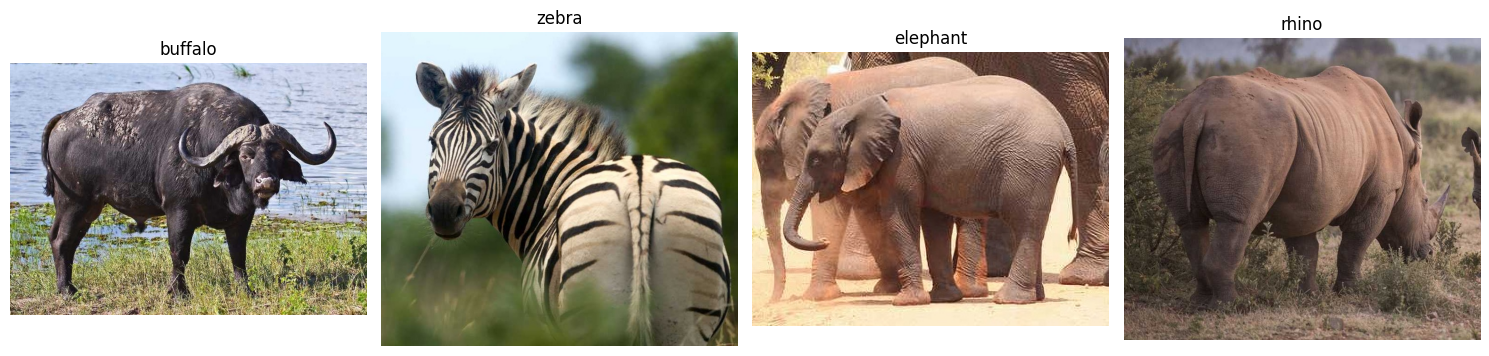

In [18]:
import random

counts = {s: {n: len(list((cls_root/s/n).glob('*.jpg'))) for n in names} for s in ['train','val']}
print(counts)

fig, ax = plt.subplots(1, 4, figsize=(15, 5))
chosen_classes = random.sample(names, min(4, len(names))) # Choose up to 3 random classes

for i, class_name in enumerate(chosen_classes):
    class_path = cls_root / 'train' / class_name
    images_in_class = list(class_path.glob('*.jpg'))
    if images_in_class:
        random_image_path = random.choice(images_in_class)
        ax[i].imshow(Image.open(random_image_path))
        ax[i].set_title(class_name)
        ax[i].axis('off')
    else:
        ax[i].set_title(f"No images found for {class_name}")
        ax[i].axis('off')

plt.tight_layout()
plt.show()

# Section 4: Model Definition


In [8]:
detector = YOLO('yolo26n.pt')
classifier = YOLO('yolo26n-cls.pt')
print('detector:', detector.model.yaml.get('task', 'detect'))
print('classifier:', classifier.model.yaml.get('task', 'classify'))

detector: detect
classifier: classify


# Section 4: Train the Model


In [9]:
detector.train(data='african-wildlife.yaml', epochs=10, imgsz=640, batch=16, project='/content/runs', name='detector')
classifier.train(data=str(cls_root), epochs=10, imgsz=224, batch=32, project='/content/runs', name='classifier')
detector = YOLO('/content/runs/detector/weights/best.pt')
classifier = YOLO('/content/runs/classifier/weights/best.pt')

Ultralytics 8.4.133 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detector, nbs=64, nms=False, opset=None, 


0: 352x640 1 buffalo, 10.5ms
Speed: 2.2ms preprocess, 10.5ms inference, 0.5ms postprocess per image at shape (1, 3, 352, 640)

0: 224x224 buffalo 1.00, elephant 0.00, zebra 0.00, rhino 0.00, 4.2ms
Speed: 4.3ms preprocess, 4.2ms inference, 0.0ms postprocess per image at shape (1, 3, 224, 224)


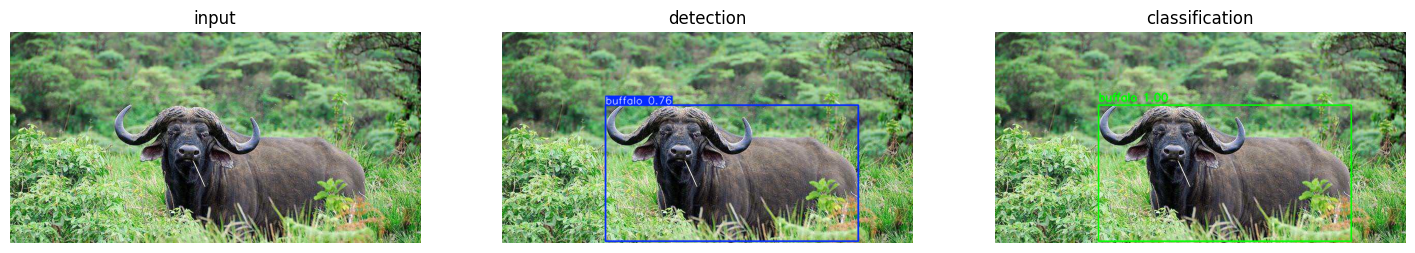

['buffalo 1.00']


In [13]:
p = val_images[0]
im = cv2.imread(str(p))
r = detector(im, conf=.35)[0]
out = im.copy(); labels = []
for j, b in enumerate(r.boxes):
    x1,y1,x2,y2 = b.xyxy[0].cpu().numpy().astype(int)
    crop = im[max(0,y1):y2, max(0,x1):x2]
    if crop.size == 0: continue
    q = classifier(crop, imgsz=224)[0]
    s = q.names[int(q.probs.top1)]; conf = float(q.probs.top1conf); labels.append(f'{s} {conf:.2f}')
    cv2.rectangle(out,(x1,y1),(x2,y2),(0,255,0),2); cv2.putText(out,labels[-1],(x1,max(20,y1-8)),0,.7,(0,255,0),2)
fig, ax = plt.subplots(1,3,figsize=(18,6))
ax[0].imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB)); ax[0].set_title('input')
ax[1].imshow(cv2.cvtColor(r.plot(),cv2.COLOR_BGR2RGB)); ax[1].set_title('detection')
ax[2].imshow(cv2.cvtColor(out,cv2.COLOR_BGR2RGB)); ax[2].set_title('classification')
for a in ax: a.axis('off')
plt.show(); print(labels)

# Section 5: Model Evaluation


In [29]:
det_metrics = detector.val(data='african-wildlife.yaml', plots=True)
cls_metrics = classifier.val(data=str(cls_root), plots=True)

print('detection mAP50-95:', det_metrics.box.map)
print('classification top1:', cls_metrics.top1)

Ultralytics 8.4.133 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1154.0±573.1 MB/s, size: 43.8 KB)
val: Scanning /content/datasets/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 59.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.5it/s 4.3s
                   all        225        379       0.88      0.815      0.892      0.743
               buffalo         62         89      0.932      0.774      0.899      0.747
              elephant         53         91      0.844      0.835      0.866      0.699
                 rhino         55         85      0.893       0.88       0.93      0.831
                 zebra         59        114      0.852      0.772      0.872      0.697
Speed: 2.5ms preprocess, 4.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs


Displaying Classification Confusion Matrix:


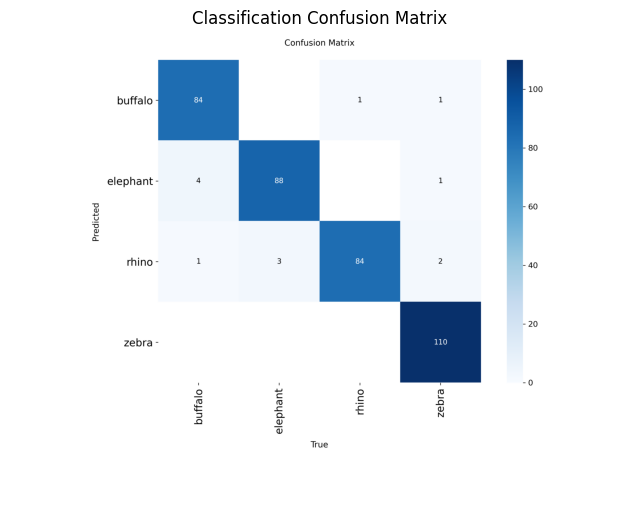


Per-Class Test Accuracy:
Class 'buffalo': 97.67% test accuracy
Class 'elephant': 94.62% test accuracy
Class 'rhino': 93.33% test accuracy
Class 'zebra': 100.00% test accuracy

Displaying Misclassified Images from Classifier Validation Set:
Found 13 misclassified images. Displaying all:


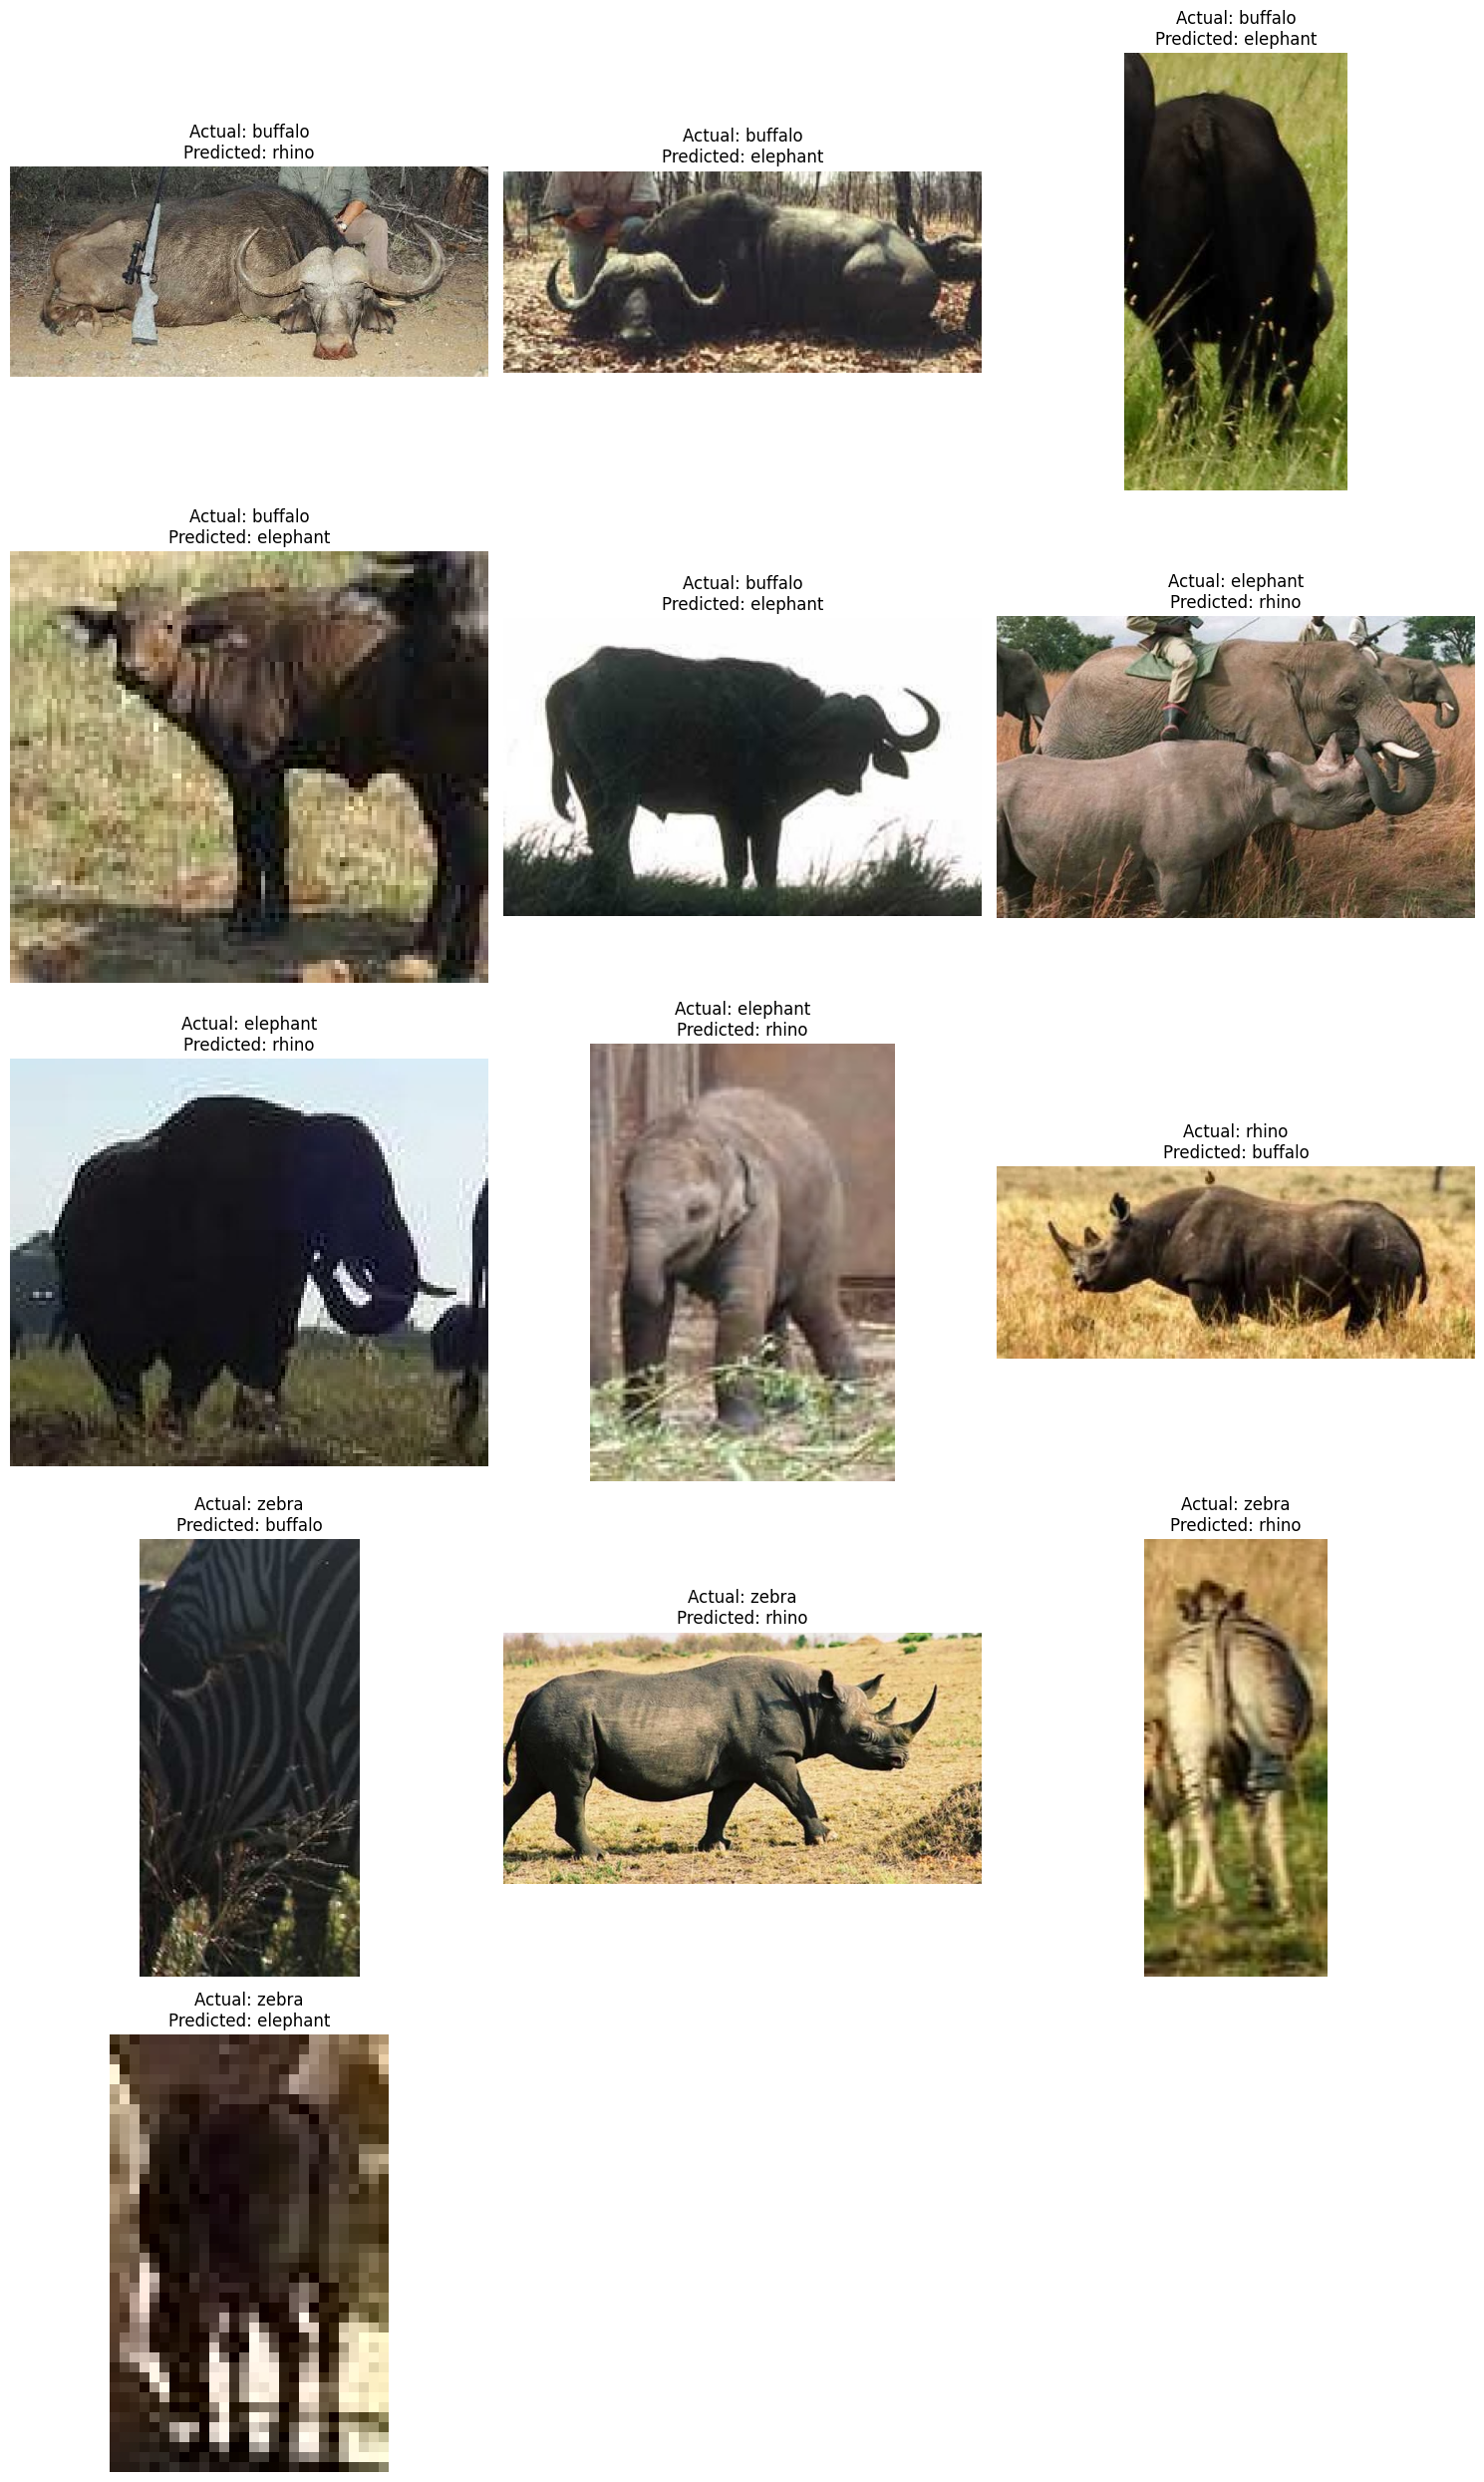

In [41]:
print('\nDisplaying Classification Confusion Matrix:')
plt.figure(figsize=(8, 8))
plt.imshow(plt.imread('/content/runs/classify/val-6/confusion_matrix.png'))
plt.title('Classification Confusion Matrix')
plt.axis('off')
plt.show()

print('\nPer-Class Test Accuracy:')
confusion_matrix_data = cls_metrics.confusion_matrix.matrix # Get the raw confusion matrix
for i, class_name in enumerate(names):
    true_positives = confusion_matrix_data[i, i]
    total_actual_for_class = np.sum(confusion_matrix_data[i, :])
    if total_actual_for_class > 0:
        accuracy = (true_positives / total_actual_for_class) * 100
        print(f"Class '{class_name}': {accuracy:.2f}% test accuracy")
    else:
        print(f"Class '{class_name}': No samples for this class in validation set.")

print('\nDisplaying Misclassified Images from Classifier Validation Set:')

misclassified_data = []

# Loop through each actual class in the validation set
for actual_class_name in names:
    class_val_dir = cls_root / 'val' / actual_class_name
    for img_path in class_val_dir.glob('*.jpg'):
        img = cv2.imread(str(img_path))
        if img is None:
            continue

        # Perform classification with verbose=False to suppress output
        results = classifier(img, imgsz=224, verbose=False)[0]
        predicted_class_idx = int(results.probs.top1)
        predicted_class_name = names[predicted_class_idx]

        # Check for misclassification
        if predicted_class_name != actual_class_name:
            misclassified_data.append({
                'image': cv2.cvtColor(img, cv2.COLOR_BGR2RGB), # Store RGB for matplotlib
                'actual': actual_class_name,
                'predicted': predicted_class_name
            })

if not misclassified_data:
    print('No misclassified images found in the classifier validation set.')
else:
    print(f'Found {len(misclassified_data)} misclassified images. Displaying all:')
    # Display misclassified images, 3 per row
    num_misclassified = len(misclassified_data)
    cols = 3
    # Calculate rows needed, ensuring at least 1 row if there are images
    rows = (num_misclassified + cols - 1) // cols if num_misclassified > 0 else 0

    if rows > 0:
        fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
        # Ensure axes is always iterable, even for single subplot
        axes = np.array(axes).flatten()

        for i, item in enumerate(misclassified_data):
            ax = axes[i]
            ax.imshow(item['image'])
            ax.set_title(f"Actual: {item['actual']}\nPredicted: {item['predicted']}")
            ax.axis('off')

        # Turn off any unused subplots if there are more axes than images
        for j in range(i + 1, len(axes)):
            axes[j].axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print('No misclassified images to display after all.')